In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

Explanation of each library
Library / function	Purpose
pandas	Works with tabular data
matplotlib.pyplot	Creates graphs
load_iris	Loads the Iris flower dataset
train_test_split	Splits data into training and testing sets
GaussianNB	Creates the Naive Bayes model
accuracy_score	Calculates prediction accuracy
classification_report	Shows precision, recall and F1-score
confusion_matrix	Counts correct and incorrect predictions
ConfusionMatrixDisplay	Displays the confusion matrix as a graph

In [2]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['target'] = iris.target

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Explanation
- load_iris() loads a sample dataset containing 150 flower records.
- iris.data contains four numerical features.
- pd.DataFrame() converts the data into a table.
- iris.feature_names provides the column names.
- df['target'] adds the flower category as the target column.
- df.head() displays the first five rows.

In [3]:
print(iris.target_names)
print(df['target'].value_counts())

['setosa' 'versicolor' 'virginica']
target
0    50
1    50
2    50
Name: count, dtype: int64


iris.target_names displays the three flower species.
value_counts() counts the number of records in each target class.

In [4]:
X = df.drop('target', axis=1)

y = df['target']

print(X.head())
print(y.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 120
Testing records: 30


In [6]:
model = GaussianNB()

print(model)

GaussianNB()


In [7]:
model.fit(X_train, y_train)

print("Model training completed")

Model training completed


In [8]:
y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("Predicted values:")
print(y_pred)

Actual values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]


In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.9666666666666667
Accuracy percentage: 96.66666666666667 %


In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



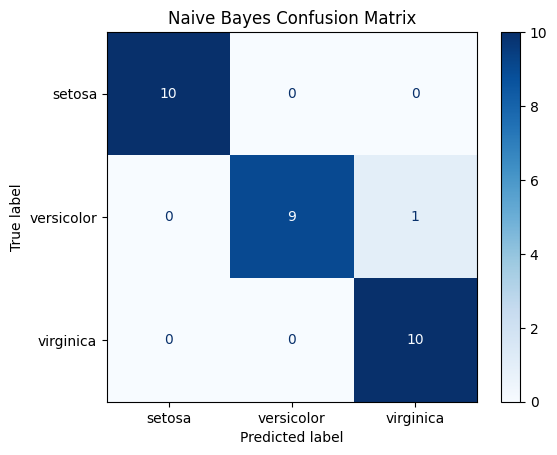

In [11]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display.plot(cmap='Blues')

plt.title("Naive Bayes Confusion Matrix")
plt.show()

Multinomial Naive Bayes and Bernoulli Naive Bayes

In [12]:
!pip install ucimlrepo

Defaulting to user installation because normal site-packages is not writeable


In [16]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep='\t',
    header=None,
    names=['label', 'message']
)

df = df[['message', 'label']]

print(df.head())

                                             message label
0  Go until jurong point, crazy.. Available only ...   ham
1                      Ok lar... Joking wif u oni...   ham
2  Free entry in 2 a wkly comp to win FA Cup fina...  spam
3  U dun say so early hor... U c already then say...   ham
4  Nah I don't think he goes to usf, he lives aro...   ham


In [17]:
print("Dataset shape:", df.shape)

print("\nLabel counts:")
print(df['label'].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5572, 2)

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
message    0
label      0
dtype: int64


In [18]:
X = df['message']
y = df['label']

print("Input data:")
print(X.head())

print("\nOutput labels:")
print(y.head())

Input data:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: object

Output labels:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 4457
Testing records: 1115


In [20]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

X_train_count = vectorizer.fit_transform(X_train)
X_test_count = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_count.shape)
print("Testing matrix shape:", X_test_count.shape)

Training matrix shape: (4457, 7668)
Testing matrix shape: (1115, 7668)


In [21]:
from sklearn.naive_bayes import MultinomialNB

model_multi = MultinomialNB()

model_multi.fit(X_train_count, y_train)

print("Model training completed")

Model training completed


In [22]:
from sklearn.metrics import accuracy_score

y_pred_multi = model_multi.predict(X_test_count)

accuracy = accuracy_score(y_test, y_pred_multi)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.9874439461883409
Accuracy percentage: 98.7443946188341 %


In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_multi))

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.99      0.92      0.95       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [24]:
new_message = ["Congratulations! You have won a free prize. Call now!"]

new_message_count = vectorizer.transform(new_message)

prediction = model_multi.predict(new_message_count)

print("Message:", new_message[0])
print("Predicted category:", prediction[0])

Message: Congratulations! You have won a free prize. Call now!
Predicted category: spam


In [25]:
new_message = ["Hi, how are you? Are we meeting today?"]

new_message_count = vectorizer.transform(new_message)

prediction = model_multi.predict(new_message_count)

print("Message:", new_message[0])

if prediction[0] == "ham":
    print("Prediction: Not Spam")
else:
    print("Prediction: Spam")

Message: Hi, how are you? Are we meeting today?
Prediction: Not Spam
